# Підсумковий проект Reuse Science

Для виконання цього підсумкового проекту я обрала вбудований в бібліотеку seaborn датасет - exercise, в якому подана інформація про фізичні вправи і частоту пульсу.

## Етап 1. Завантаження та попереднє дослідження даних



In [ ]:
import seaborn as sns
import pandas as pd
import numpy as np

df = sns.load_dataset('exercise')
df.head()

,Unnamed: 0,id,diet,pulse,time,kind
0,0,1,low fat,85,1 min,rest
1,1,1,low fat,85,15 min,rest
2,2,1,low fat,88,30 min,rest
3,3,2,low fat,90,1 min,rest
4,4,2,low fat,92,15 min,rest


In [ ]:
df

,Unnamed: 0,id,diet,pulse,time,kind
0,0,1,low fat,85,1 min,rest
1,1,1,low fat,85,15 min,rest
2,2,1,low fat,88,30 min,rest
3,3,2,low fat,90,1 min,rest
4,4,2,low fat,92,15 min,rest
...,...,...,...,...,...,...
85,85,29,no fat,135,15 min,running
86,86,29,no fat,130,30 min,running
87,87,30,no fat,99,1 min,running
88,88,30,no fat,111,15 min,running


In [ ]:
df.apply(lambda x: x.unique())

,0
Unnamed: 0,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
id,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
diet,"['low fat', 'no fat'] Categories (2, object): ..."
pulse,"[85, 88, 90, 92, 93, 97, 94, 80, 82, 83, 91, 8..."
time,"['1 min', '15 min', '30 min'] Categories (3, o..."
kind,"['rest', 'walking', 'running'] Categories (3, ..."


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
id,0
diet,0
pulse,0
time,0
kind,0


### Пропущених значень немає, отже, можемо переходити до аналізу та візуалізацій

# Етап 2. Feature Engineering

Додамо нову колонку, в якій буде позначка про те, чи пульс є нормальним, чи ні. Критерієм норми для дорослого є діапазон від 60 до 100 ударів/хв.

In [ ]:
df['pulse_normal'] = np.where((df['pulse'] > 60) & (df['pulse'] < 100), 'normal', 'unusual')

df

,Unnamed: 0,id,diet,pulse,time,kind,pulse_normal
0,0,1,low fat,85,1 min,rest,normal
1,1,1,low fat,85,15 min,rest,normal
2,2,1,low fat,88,30 min,rest,normal
3,3,2,low fat,90,1 min,rest,normal
4,4,2,low fat,92,15 min,rest,normal
...,...,...,...,...,...,...,...
85,85,29,no fat,135,15 min,running,unusual
86,86,29,no fat,130,30 min,running,unusual
87,87,30,no fat,99,1 min,running,normal
88,88,30,no fat,111,15 min,running,unusual


# Етап 3. Аналіз даних: групування та агрегування

У цьому датасеті можна погрупувати дані за критерієм дієти (3.1.) та типом актвиності (3.2).  

## 3.1. Аналіз даних за криетрієм "тип дієти"

In [ ]:
grouped_by_diet=df['diet'].value_counts()
grouped_by_diet

,count
diet,
no fat,45
low fat,45


## 3.2. Групування даних за критерієм "тип активності"

In [ ]:
activity=df.groupby('time')['diet'].value_counts()
activity

<ipython-input-42-7e99bcc8f463>:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  activity=df.groupby('time')['diet'].value_counts()


time    diet   
1 min   no fat     15
        low fat    15
15 min  no fat     15
        low fat    15
30 min  no fat     15
        low fat    15
Name: count, dtype: int64

На цьому етапі бачимо, що дані виглядають "ідеально", бо у кожній з виділених груп по оданковій кількості екземплярів.

# Етап 4. Візуалізація даних

In [ ]:
Робити візуалізації по 3.1. та 3.2. буде неіформативно, тому можемо робити наприклад, графік пульсу залежно від тривалості тренування (у вигляді box plot) та середній пульс залежно від типу дієти.

<Figure size 1000x600 with 0 Axes>

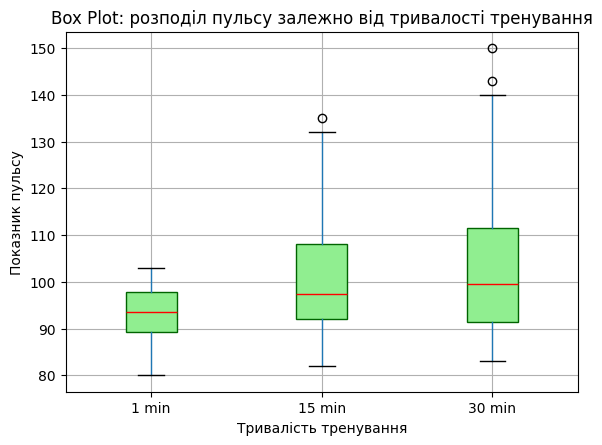

In [ ]:
plt.figure(figsize=(10,6))
df.boxplot(column='pulse', by='time', patch_artist=True,
             boxprops={'facecolor': 'lightgreen', 'color': 'darkgreen'},
             medianprops={'color': 'red'})
plt.title("Box Plot: розподіл пульсу залежно від тривалості тренування")
plt.suptitle('')
plt.xlabel("Тривалість тренування")
plt.ylabel("Показник пульсу")
plt.show()

<ipython-input-59-5cbc6b2a6b93>:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_pulse = df.groupby('diet')['pulse'].mean()


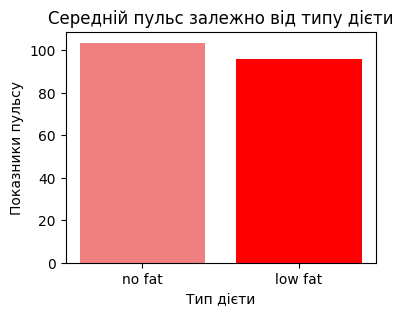

In [ ]:
mean_pulse = df.groupby('diet')['pulse'].mean()

plt.figure(figsize=(4,3))

plt.bar(mean_pulse.index, mean_pulse.values, color= ['lightcoral','red'])
plt.title("Середній пульс залежно від типу дієти")
plt.xlabel("Тип дієти")
plt.ylabel("Показники пульсу")
plt.show()


# **ВИСНОВКИ**

За результатами проведеного аналізу та візуалізації,  можемо зробити такі висновки:
- взятий для прикладу датасет exercises з біблотеки seaborn *практично ідлаьний:* без пропущених значень, з рівномірним поділом по групах і т.д.

- по **box plot** бачимо, що дані показників пульсу досить розкидані (асиметричні, не дуже репрезентативні), та мають викиди, що може свідчити, зкоерма,   про помилки в вимірюваннях, або ж бути варіантом рідкісного випадку. При цьому зі збільшенням тривалості тренування викидів стає більше, що можна інтерпретувати як те, що в кожної людини показники пульсу можуть бути абсолютно різними ,попри медичну норму.

- по **bar chart** бачимо, що різниця між середнім покзаником пульсу у тих, хто має низько- та висококалорійну дієту практично несуттєва (близько 97-105 уд/хв).